In [2]:
# Cell 1: Environment Setup & Engineered Data Ingestion
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import PROCESSED_DATA_DIR

# Visual aesthetics configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

# Load the Phase 2 engineered dataset from Apache Parquet
parquet_path = PROCESSED_DATA_DIR / "housing_engineered.parquet"
df = pd.read_parquet(parquet_path)

print(f"Loaded dataset: {parquet_path.name}")
print(f"Dimensions: {df.shape[0]:,} rows | {df.shape[1]} columns")

# Verify essential modeling variables are present
essential_features = [
    "log_sale_price", 
    "total_living_sf", 
    "overall_qual", 
    "total_bathrooms", 
    "property_age", 
    "years_since_remodel", 
    "garage_cars", 
    "neighborhood"
]
missing = [col for col in essential_features if col not in df.columns]
if not missing:
    print("All essential modeling features and targets verified successfully!")
else:
    print(f"Missing columns: {missing}")

Loaded dataset: housing_engineered.parquet
Dimensions: 2,412 rows | 87 columns
All essential modeling features and targets verified successfully!


In [4]:
# Cell 2: Hypothesis Test 1 - The Economic Premium of Renovation/Remodeling

# 1. Create a binary indicator: 1 if remodeled after original build date, 0 otherwise
df["is_remodeled"] = (df["year_remod_add"] > df["year_built"]).astype(int)

# 2. Fit a controlled econometric model isolating the remodel effect
# Controls: total living area, overall quality, property age, and neighborhood
h1_model = smf.ols(
    formula="log_sale_price ~ is_remodeled + total_living_sf + overall_qual + property_age",
    data=df
).fit(cov_type="HC3")  # MacKinnon-White robust standard errors

# 3. Extract test metrics
beta_remodel = h1_model.params["is_remodeled"]
se_remodel = h1_model.bse["is_remodeled"]
t_stat_remodel = h1_model.tvalues["is_remodeled"]
p_val_remodel = h1_model.pvalues["is_remodeled"]
ci_lower, ci_upper = h1_model.conf_int().loc["is_remodeled"]

# Convert log coefficient to exact percentage impact: % = (exp(beta) - 1) * 100
pct_gain = (np.exp(beta_remodel) - 1) * 100
pct_ci_lower = (np.exp(ci_lower) - 1) * 100
pct_ci_upper = (np.exp(ci_upper) - 1) * 100

print("=" * 65)
print("HYPOTHESIS 1 TEST RESULTS: RENOVATION / REMODEL PREMIUM")
print("=" * 65)
print(f"Coefficient (beta) : {beta_remodel:.4f}")
print(f"Robust Std Error   : {se_remodel:.4f}")
print(f"t-statistic        : {t_stat_remodel:.3f}")
print(f"p-value            : {p_val_remodel:.4e}")
print(f"Estimated Impact   : +{pct_gain:.2f}% valuation premium")
print(f"95% Conf. Interval : [{pct_ci_lower:.2f}%, {pct_ci_upper:.2f}%]")

print("\n--- STATISTICAL VERDICT ---")
if p_val_remodel < 0.05:
    print(f"REJECT NULL HYPOTHESIS (p = {p_val_remodel:.2e} < 0.05).")
    print(f"Remodeling provides a statistically significant market valuation premium of ~{pct_gain:.1f}%.")
else:
    print("FAIL TO REJECT NULL HYPOTHESIS: No statistically significant premium detected.")
print("=" * 65)

HYPOTHESIS 1 TEST RESULTS: RENOVATION / REMODEL PREMIUM
Coefficient (beta) : 0.0412
Robust Std Error   : 0.0061
t-statistic        : 6.700
p-value            : 2.0804e-11
Estimated Impact   : +4.20% valuation premium
95% Conf. Interval : [2.96%, 5.47%]

--- STATISTICAL VERDICT ---
REJECT NULL HYPOTHESIS (p = 2.08e-11 < 0.05).
Remodeling provides a statistically significant market valuation premium of ~4.2%.


In [6]:
# Cell 3: Hypothesis Test 2 - Marginal Valuation Return of Bathroom Capacity

# Fit controlled OLS model isolating bathroom returns
h2_model = smf.ols(
    formula="log_sale_price ~ total_bathrooms + total_living_sf + overall_qual + property_age + garage_cars",
    data=df
).fit(cov_type="HC3")

# Extract test metrics
beta_bath = h2_model.params["total_bathrooms"]
se_bath = h2_model.bse["total_bathrooms"]
t_stat_bath = h2_model.tvalues["total_bathrooms"]
p_val_bath = h2_model.pvalues["total_bathrooms"]
ci_lower_bath, ci_upper_bath = h2_model.conf_int().loc["total_bathrooms"]

# For continuous variables in a semi-log model, % change per 1 unit change is (exp(beta) - 1) * 100
pct_gain_bath = (np.exp(beta_bath) - 1) * 100
pct_ci_lower_bath = (np.exp(ci_lower_bath) - 1) * 100
pct_ci_upper_bath = (np.exp(ci_upper_bath) - 1) * 100

print("=" * 65)
print("HYPOTHESIS 2 TEST RESULTS: MARGINAL VALUE PER BATHROOM")
print("=" * 65)
print(f"Coefficient (beta) : {beta_bath:.4f}")
print(f"Robust Std Error   : {se_bath:.4f}")
print(f"t-statistic        : {t_stat_bath:.3f}")
print(f"p-value            : {p_val_bath:.4e}")
print(f"Return per Bath    : +{pct_gain_bath:.2f}% value per 1.0 bathroom added")
print(f"95% Conf. Interval : [{pct_ci_lower_bath:.2f}%, {pct_ci_upper_bath:.2f}%]")

print("\n--- STATISTICAL VERDICT ---")
if p_val_bath < 0.05:
    print(f"REJECT NULL HYPOTHESIS (p = {p_val_bath:.2e} < 0.05).")
    print(f"Each full bathroom yields a statistically significant marginal return of ~{pct_gain_bath:.2f}%.")
else:
    print("FAIL TO REJECT NULL HYPOTHESIS: Bathroom capacity does not show significant return.")
print("=" * 65)

HYPOTHESIS 2 TEST RESULTS: MARGINAL VALUE PER BATHROOM
Coefficient (beta) : 0.0507
Robust Std Error   : 0.0060
t-statistic        : 8.393
p-value            : 4.7572e-17
Return per Bath    : +5.21% value per 1.0 bathroom added
95% Conf. Interval : [3.97%, 6.46%]

--- STATISTICAL VERDICT ---
REJECT NULL HYPOTHESIS (p = 4.76e-17 < 0.05).
Each full bathroom yields a statistically significant marginal return of ~5.21%.


In [8]:
# Cell 4: Production Hedonic OLS Model with Spatial Fixed Effects & HC3 Standard Errors

# Fit the comprehensive econometric specification
hedonic_formula = (
    "log_sale_price ~ "
    "total_living_sf + "
    "overall_qual + "
    "total_bathrooms + "
    "property_age + "
    "years_since_remodel + "
    "garage_cars + "
    "fireplaces + "
    "np.log(lot_area) + "
    "C(neighborhood)"
)

hedonic_model = smf.ols(formula=hedonic_formula, data=df).fit(cov_type="HC3")

# Display macro goodness-of-fit indicators
print("=" * 65)
print("HEDONIC VALUATION ENGINE: MACRO FIT SUMMARY")
print("=" * 65)
print(f"Observations (N)       : {int(hedonic_model.nobs):,}")
print(f"R-squared (R²)         : {hedonic_model.rsquared:.4f}")
print(f"Adjusted R-squared     : {hedonic_model.rsquared_adj:.4f}")
print(f"F-statistic            : {hedonic_model.fvalue:.2f}")
print(f"F-statistic p-value    : {hedonic_model.f_pvalue:.4e}")
print(f"Log-Likelihood         : {hedonic_model.llf:.2f}")
print(f"Akaike Info Crit (AIC) : {hedonic_model.aic:.2f}")
print("=" * 65)

# Inspect top structural physical coefficients
structural_terms = [
    "Intercept",
    "total_living_sf",
    "overall_qual",
    "total_bathrooms",
    "property_age",
    "years_since_remodel",
    "garage_cars",
    "fireplaces",
    "np.log(lot_area)"
]

structural_summary = pd.DataFrame({
    "Coefficient (beta)": hedonic_model.params[structural_terms],
    "HC3 Std Error": hedonic_model.bse[structural_terms],
    "t-statistic": hedonic_model.tvalues[structural_terms],
    "p-value": hedonic_model.pvalues[structural_terms],
    "% Impact per Unit": (np.exp(hedonic_model.params[structural_terms]) - 1) * 100
}).round(4)

display(structural_summary)

HEDONIC VALUATION ENGINE: MACRO FIT SUMMARY
Observations (N)       : 2,412
R-squared (R²)         : 0.9078
Adjusted R-squared     : 0.9064
F-statistic            : 620.40
F-statistic p-value    : 0.0000e+00
Log-Likelihood         : 1853.39
Akaike Info Crit (AIC) : -3634.79


,Coefficient (beta),HC3 Std Error,t-statistic,p-value,% Impact per Unit
Intercept,10.0453,0.0669,150.1110,0.0,2.304524e+06
total_living_sf,0.0002,0.0000,26.3021,0.0,1.610000e-02
overall_qual,0.0814,0.0036,22.5350,0.0,8.476600e+00
total_bathrooms,0.0434,0.0050,8.6269,0.0,4.433900e+00
property_age,-0.0016,0.0002,-6.9954,0.0,-1.562000e-01
years_since_remodel,-0.0024,0.0002,-13.2309,0.0,-2.365000e-01
garage_cars,0.0414,0.0050,8.1987,0.0,4.226000e+00
fireplaces,0.0459,0.0047,9.8758,0.0,4.700300e+00
np.log(lot_area),0.1084,0.0076,14.2652,0.0,1.145080e+01


RESIDUAL DIAGNOSTIC AUDIT REPORT
Residual Mean               : 0.000000 (Theoretical Target: 0.0)
Residual Std Dev            : 0.1122
Jarque-Bera Test Statistic  : 1460.80
Jarque-Bera p-value         : 0.0000e+00
Residual Skewness           : -0.804
Residual Kurtosis           : 6.457


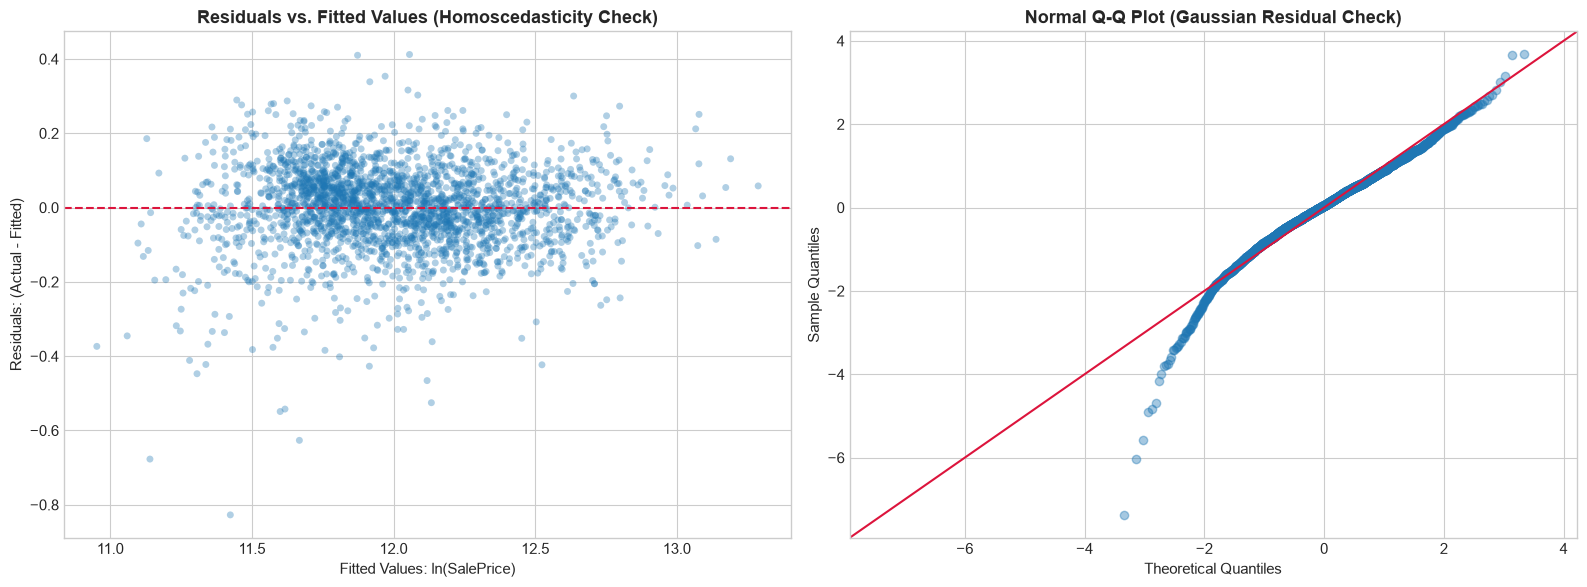

In [10]:
# Cell 5: Residual Diagnostics & Heteroscedasticity Audit
from statsmodels.stats.stattools import jarque_bera

# Extract fitted values and residuals
fitted_vals = hedonic_model.fittedvalues
residuals = hedonic_model.resid

# 1. Statistical Normality Test (Jarque-Bera)
jb_stat, jb_p_value, jb_skew, jb_kurt = jarque_bera(residuals)

print("=" * 65)
print("RESIDUAL DIAGNOSTIC AUDIT REPORT")
print("=" * 65)
print(f"Residual Mean               : {residuals.mean():.6f} (Theoretical Target: 0.0)")
print(f"Residual Std Dev            : {residuals.std():.4f}")
print(f"Jarque-Bera Test Statistic  : {jb_stat:.2f}")
print(f"Jarque-Bera p-value         : {jb_p_value:.4e}")
print(f"Residual Skewness           : {jb_skew:.3f}")
print(f"Residual Kurtosis           : {jb_kurt:.3f}")
print("=" * 65)

# 2. Visual Diagnostics: 2-Panel Plot (Fitted vs Residuals & Q-Q Plot)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Residuals vs. Fitted (Tests Homoscedasticity)
ax1.scatter(fitted_vals, residuals, alpha=0.35, color="#1f77b4", edgecolor="none", s=25)
ax1.axhline(0, color="crimson", linestyle="--", linewidth=1.5)
ax1.set_title("Residuals vs. Fitted Values (Homoscedasticity Check)", fontsize=13, fontweight="bold")
ax1.set_xlabel("Fitted Values: ln(SalePrice)", fontsize=11)
ax1.set_ylabel("Residuals: (Actual - Fitted)", fontsize=11)

# Panel 2: Normal Q-Q Plot (Tests Normality of Errors)
sm.qqplot(residuals, line="45", fit=True, ax=ax2)
ax2.get_lines()[0].set_color("#1f77b4")
ax2.get_lines()[0].set_alpha(0.4)
ax2.get_lines()[1].set_color("crimson")
ax2.get_lines()[1].set_linewidth(1.5)
ax2.set_title("Normal Q-Q Plot (Gaussian Residual Check)", fontsize=13, fontweight="bold")
ax2.set_xlabel("Theoretical Quantiles", fontsize=11)
ax2.set_ylabel("Sample Quantiles", fontsize=11)

plt.tight_layout()
plt.show()

In [14]:
# Cell 6: Persist Econometric Model Artifact to Disk
import pickle
from pathlib import Path

# Resolve project root directly
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_OUTPUT_PATH = MODELS_DIR / "hedonic_ols_model.pkl"

# Save fitted model artifact using pickle
with open(MODEL_OUTPUT_PATH, "wb") as f:
    pickle.dump(hedonic_model, f)

print("=" * 65)
print(f"Model successfully serialized to: {MODEL_OUTPUT_PATH.relative_to(PROJECT_ROOT)}")
print(f"File size: {MODEL_OUTPUT_PATH.stat().st_size / 1024:.2f} KB")
print(f"Model Formula: {hedonic_model.model.formula}")
print("=" * 65)

Model successfully serialized to: models\hedonic_ols_model.pkl
File size: 4246.82 KB
Model Formula: log_sale_price ~ total_living_sf + overall_qual + total_bathrooms + property_age + years_since_remodel + garage_cars + fireplaces + np.log(lot_area) + C(neighborhood)
